# Understanding what drives Interest Rates using Linear Regression

This is just a simple linear regression workflow to demonstrate the basics.

In [44]:
import pandas as pd

## Understanding the Data

In [45]:
df = pd.read_csv("/kaggle/input/datasets/laotse/credit-risk-dataset/credit_risk_dataset.csv")
print(df.shape)
print(df.head())

(32581, 12)
   person_age  person_income person_home_ownership  person_emp_length  \
0          22          59000                  RENT              123.0   
1          21           9600                   OWN                5.0   
2          25           9600              MORTGAGE                1.0   
3          23          65500                  RENT                4.0   
4          24          54400                  RENT                8.0   

  loan_intent loan_grade  loan_amnt  loan_int_rate  loan_status  \
0    PERSONAL          D      35000          16.02            1   
1   EDUCATION          B       1000          11.14            0   
2     MEDICAL          C       5500          12.87            1   
3     MEDICAL          C      35000          15.23            1   
4     MEDICAL          C      35000          14.27            1   

   loan_percent_income cb_person_default_on_file  cb_person_cred_hist_length  
0                 0.59                         Y                   

In [46]:
print(df.dtypes)

person_age                      int64
person_income                   int64
person_home_ownership          object
person_emp_length             float64
loan_intent                    object
loan_grade                     object
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file      object
cb_person_cred_hist_length      int64
dtype: object


In [47]:
print(df.describe())

         person_age  person_income  person_emp_length     loan_amnt  \
count  32581.000000   3.258100e+04       31686.000000  32581.000000   
mean      27.734600   6.607485e+04           4.789686   9589.371106   
std        6.348078   6.198312e+04           4.142630   6322.086646   
min       20.000000   4.000000e+03           0.000000    500.000000   
25%       23.000000   3.850000e+04           2.000000   5000.000000   
50%       26.000000   5.500000e+04           4.000000   8000.000000   
75%       30.000000   7.920000e+04           7.000000  12200.000000   
max      144.000000   6.000000e+06         123.000000  35000.000000   

       loan_int_rate   loan_status  loan_percent_income  \
count   29465.000000  32581.000000         32581.000000   
mean       11.011695      0.218164             0.170203   
std         3.240459      0.413006             0.106782   
min         5.420000      0.000000             0.000000   
25%         7.900000      0.000000             0.090000   
50%   

Evaluating the values of the attributes. For example shows "person_age" and "person_emp_length" go higher than 120 years which cant be possible entries as of current living standards. These need to be dealth with when cleaning the data.

In [48]:
print(df.isnull().sum())

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64


Missing values in our target column "loan_int_rate" and "person_emp_length". Dropping data points with null in the target column makes the most sense. Need to decide what to do with "person_emp_length" null values. 

In [49]:
print((df['person_age'] > 100).sum())
print((df['person_emp_length'] > 100).sum()) 

5
2


<Axes: >

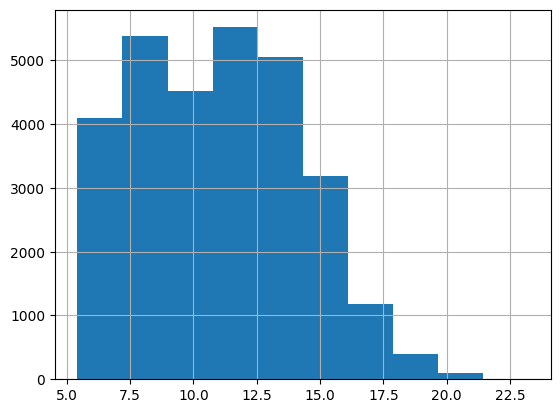

In [50]:
df["loan_int_rate"].hist()

Target data is roughly bell shaped, meaning linear regression should work fine on the data set.  

## Preparing the Data

### Outliers, Impossible and Missing Values

As said before, I am dropping the obvious out-of-range data in age and employment length, since theyre impossible values and keeping them would distort the learned relationships. I'm also dropping the rows with null values in interest rate column, since imputing would require assuming the target value. As I am not familiar with the feature relationships yet, I do not want to insert guesses and since the data set contains around 29k rows now, dropping rows with null values in employment length is a cheap price for an assumption-free data set.

In [51]:
df = df[df['person_age'] <= 100]
df = df[df['person_emp_length'] <= 100]

df = df[df["loan_int_rate"].notnull()]

df = df[df["person_emp_length"].notnull()]

### Encoding Categorial Features

Categorial Columns being: person_home_ownership, loan_intent, loan_grade, cb_person_default_on_file

Where one-hot encoding "person_home_ownership", "loan_intent" and "cb_person_default_on_file" makes sense, since they aren't ordered and plain categorial features. However "loan_grade" contains a ranking, where the order matters, so one-hot encoding would lead to the ranking information getting lost. For simplicity I am assuming that loan grade ranking is evenly spaced and am therefore mapping it to numbers.

In [52]:
df = pd.get_dummies(df, columns=["person_home_ownership", "loan_intent", "cb_person_default_on_file"], drop_first=True)

grade_mapping = {"A": 1, "B": 2, "C": 3, "D": 4, "E": 5, "F": 6, "G": 7}
df["loan_grade"] = df["loan_grade"].map(grade_mapping)

### Train and Test Split

In [53]:
from sklearn.model_selection import train_test_split

In [54]:
X = df.drop("loan_int_rate", axis=1)
y = df["loan_int_rate"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=9)

## Fitting the Model

Linear regression has a closed form solution. The weights that minimize the squared error are given by $w = (X^T X)^{-1} X^T y$.

In [55]:
from sklearn.linear_model import LinearRegression

In [56]:
model = LinearRegression().fit(X_train, y_train)

## Understanding the Model

### Interpreting the coefficients

Mapping each coefficient to its respective column, for easier inspection (since "model.coef_" only returns a simple array).

In [57]:
coefficient_table = pd.DataFrame({"feature": X_train.columns,
                                  "coefficient": model.coef_}).sort_values("coefficient", key=abs, ascending=False)

print(coefficient_table)

                        feature   coefficient
3                    loan_grade  2.590457e+00
8   person_home_ownership_OTHER  2.924800e-01
5                   loan_status -2.228393e-01
10   person_home_ownership_RENT  2.178698e-01
6           loan_percent_income  1.905662e-01
9     person_home_ownership_OWN  1.532983e-01
11        loan_intent_EDUCATION -4.859385e-02
12  loan_intent_HOMEIMPROVEMENT -4.209677e-02
15          loan_intent_VENTURE -3.689187e-02
13          loan_intent_MEDICAL -2.567883e-02
7    cb_person_cred_hist_length  1.302671e-02
16  cb_person_default_on_file_Y  1.226293e-02
0                    person_age -8.471526e-03
14         loan_intent_PERSONAL -3.982612e-03
2             person_emp_length -3.735541e-03
4                     loan_amnt  5.116572e-06
1                 person_income -6.497558e-09


As expected loan grade strongly influences the expected value in interest rates, which could stem from loan grade and interest rate being assigned together. Additionally loan status is most likely an outcome depending on interest rate and loan grade. So I will drop both features as well, since I want to understand the underlying factors that drive the interest rate. And in retrospect, interpretation of the importance of each of the coefficients does not make sense if I haven't standardized the magnitudes of the features.

In [58]:
from sklearn.preprocessing import StandardScaler

In [59]:
df = df.drop(["loan_grade", "loan_status"], axis=1)

X = df.drop("loan_int_rate", axis=1)
y = df["loan_int_rate"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=9)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LinearRegression().fit(X_train_scaled, y_train)

In [60]:
coefficient_table = pd.DataFrame({"feature": X_train.columns,
                                  "coefficient": model.coef_}).sort_values("coefficient", key=abs, ascending=False)

print(coefficient_table)

                        feature  coefficient
14  cb_person_default_on_file_Y     1.575129
3                     loan_amnt     0.512387
8    person_home_ownership_RENT     0.387539
1                 person_income    -0.101893
5    cb_person_cred_hist_length     0.095803
7     person_home_ownership_OWN     0.093020
2             person_emp_length    -0.086900
0                    person_age    -0.067060
6   person_home_ownership_OTHER     0.056006
4           loan_percent_income    -0.040191
10  loan_intent_HOMEIMPROVEMENT     0.030408
9         loan_intent_EDUCATION    -0.022880
11          loan_intent_MEDICAL    -0.014938
13          loan_intent_VENTURE    -0.013709
12         loan_intent_PERSONAL     0.008662


*Observations:*
- borrowers with a past default get higher interest rates
- higher loan amount leads to higher interest rate
- higher income, employment length and age seem to factor in lower interest rates
- education, venture and medical intent make interest rate go down

*Hypotheses:*
- past defaults, lead to higher risk for lenders
- high loans lead to losing more money if loan isn't paid back, meaning the overall risk is higher
- higher income, employment length and age factor in more security and maturity of the loan being paid back
- education and venture intentions could be seen as "investments", which make sense to lower the interest rate
- medical intentions seem as more of a risk to me, so it suprises me that the coefficient is negative
- gap in rent and homeownership makes sense, since having capital (owning a home) lessens the risk of the loan defaulting

Apart from the highest three coefficients, all others absolute values are below 0.1. I will have to look further into them, since they could be noise.

### Validating the Assumptions

#### Multicollinearity

In [61]:
import seaborn as sns
import matplotlib.pyplot as plt

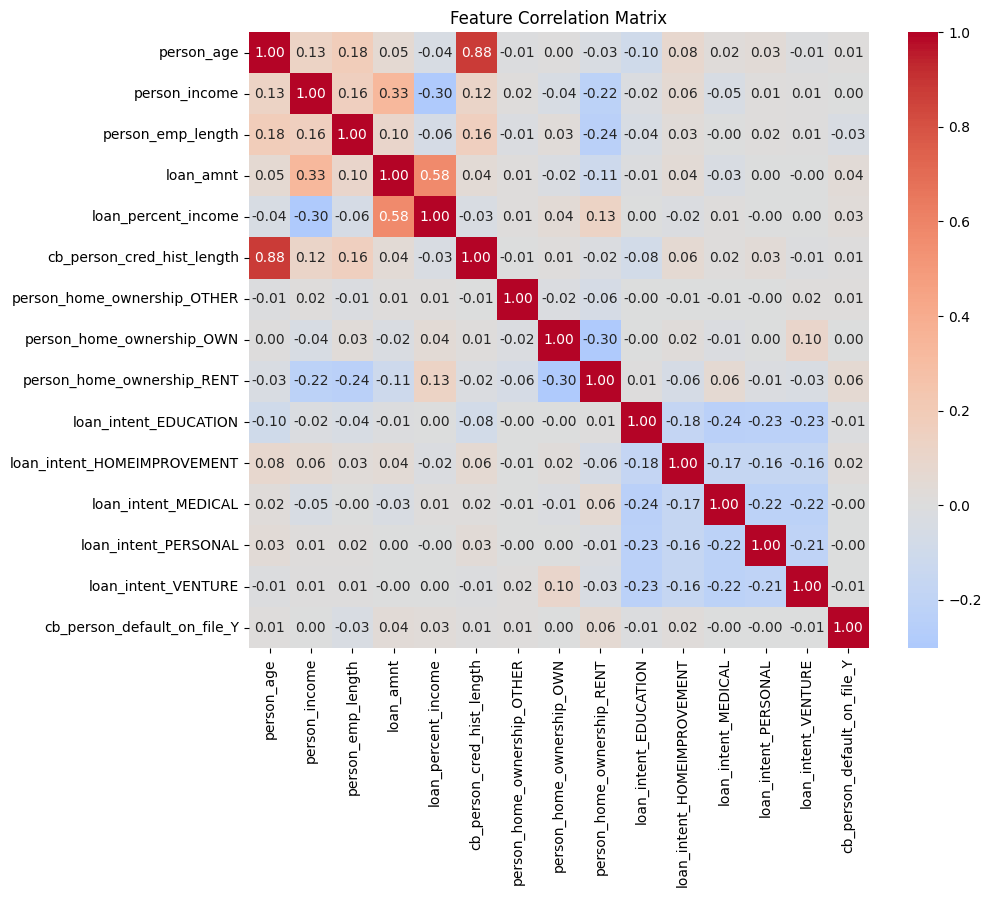

In [62]:
plt.figure(figsize=(10,8))
sns.heatmap(X_train.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Feature Correlation Matrix")
plt.show()

Person age and employment length are strongly correlated (0.88). This makes sense, since older people had more time to be employed for a longer time. The model cant split the features respective effects, which leads to each coefficient of the features coming out small. This does not seem to harm the model, but reading the coefficients of either feature needs to be done with caution. Therefore I will keep both features, rather than dropping one of the two, so I don't lose information.

Other than that loan amount and loan percent income correlate as well. Here it's important to look into what loan percent income derives from. Since loan percent income is (loan amount/ person income), which is partially redundant. However it creates new non-linear information for our model, whcih is why I won't drop that feature either as of now.

#### Plotting Residuals

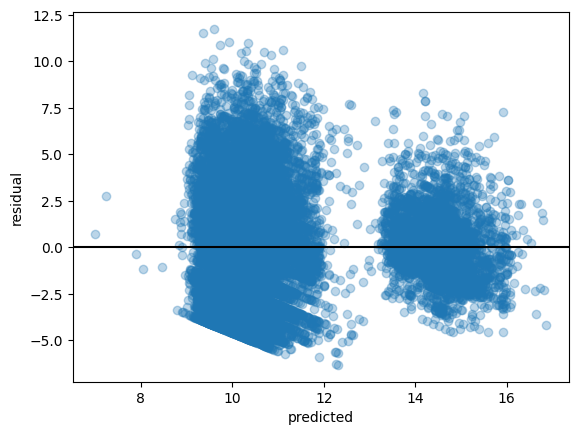

In [63]:
predicted = model.predict(X_train_scaled)
residuals = y_train - predicted
plt.scatter(predicted, residuals, alpha=0.3)
plt.axhline(0, color="black")
plt.xlabel("predicted")
plt.ylabel("residual")
plt.show()

The residual plot consists of two clouds, which could stem from a categorial feature heavily impacting the predictions into two clusters. Looking at the coefficients magnitude, it most likely is the cb_person_default_on_file_Y feature. So I'll look at the graph from that perspective.

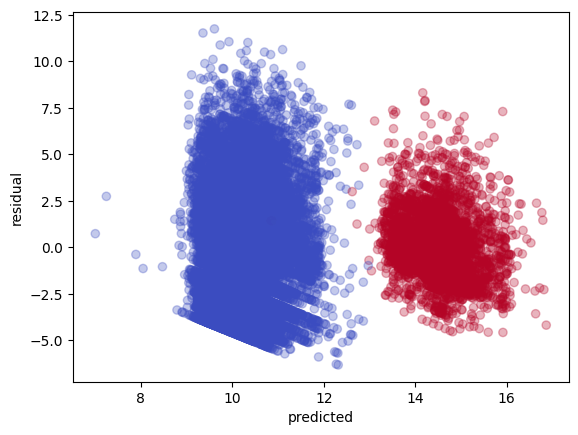

In [64]:
plt.scatter(predicted, residuals, c=X_train["cb_person_default_on_file_Y"], alpha=0.3, cmap="coolwarm")
plt.xlabel("predicted")
plt.ylabel("residual")
plt.show()

As expected, a prior default splits the predictions into two clusters. This makes sense, since defaulting on a prior loan, creates higher risk of defaulting again. So a prior default is associated with a noticeably higher rate on the next loan.

#### Residual distribution

<Axes: >

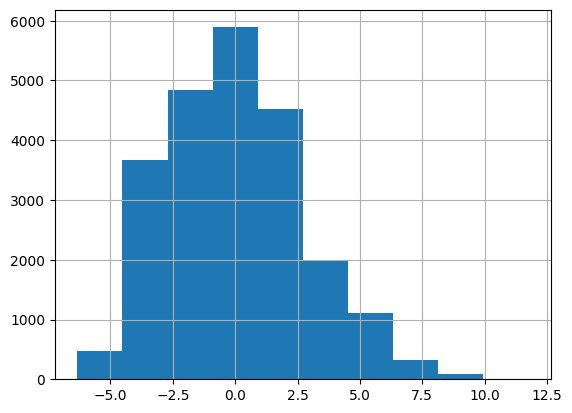

In [65]:
residuals.hist()

Residuals are roughly bell-shaped, with some deviation in the tails.

## Evaluation on the Test Set

In [66]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [67]:
y_pred = model.predict(X_test_scaled)

r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred); rmse = mse ** 0.5 # root of the MSE
mae = mean_absolute_error(y_test, y_pred)

print(f"R²:   {r2:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE:  {mae:.4f}")

R²:   0.2793
RMSE: 2.7384
MAE:  2.1958


The model accounts for around 28% why interest rates differ, given by the $R^2$-Score. The rest comes from features and other things the model does not have. Which makes sense, since I dropped loan grade and interest rate is also defined by factors outside this data set (market conditions, lender policy, etc.). 

The RMSE is larger than the MAE, meaning there is a decently large subset of errors that inflate the RMSE.  

## Conclusion

As said just now: With loan grade removed, the model accounts for 28% of why the interest rates differ. This shows that the underlying features carry less signal than the loan grades, which in itself is informative about how interest rates are set. What I can say is that the prior default is the strongest driver among the remaining features, associated with a higher rate on the next loan. Additionally the model predicts interest rates with an error of around 2.2 points (MAE), with a subset of larger errors (RMSE 2.7).

Overall with the data set containing loan grades as well as loan status, it was not well matched to the question I set myself. With more emphasis on the research question, I would invest more time and effort in finding a data set whose features are genuinely upstream of the target. However as focus here was a demonstration of linear regression, I won't dwell on it further.